In [16]:
%ls
import glob
import time
import os
import cv2
import numpy as np

from matplotlib import pyplot as plt

from driver import io_shape_dict
from driver_base import FINNExampleOverlay
from utils import (scale_coords, letterbox, 
                   non_max_suppression,  
                   visualize_boxes)
from models import Detect

from driver import io_shape_dict
from driver_base import FINNExampleOverlay

data/             inference_camera.py  qonnx/       test_outputs/
driver_base.py    inference.ipynb      resizer.bit  TinyYOLOv3DetectorDriver.py
driver.py         loaded.xclbin        resizer.hwh  utils.py
finn/             models.py            scale.npy    video_outputs/
human_counter.py  __pycache__/         test.mp4


In [9]:
driver = FINNExampleOverlay(
    bitfile_name="./resizer.bit",
    platform="zynq-iodma",
    io_shape_dict=io_shape_dict,
    batch_size=1,
    runtime_weight_dir="runtime_weights/",
)

In [10]:
test_img_folder = "./data/"
test_img_paths = glob.glob(test_img_folder + "**/*.jpg", recursive=True)
output_path = "./test_outputs/"
if not os.path.exists(output_path):
    os.makedirs(output_path)

In [11]:
names = ['person']
nc = 1
anchors = np.array([[10,14,23,27,37,58]]) / np.array([32])
scale = np.load("scale.npy")
detect_head = Detect(nc, anchors)

img_size = (416, 416)
conf_thres = 0.10
iou_thres = 0.5

16 person


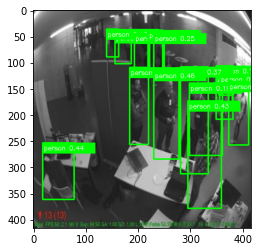

15 person


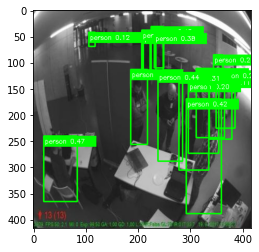

11 person


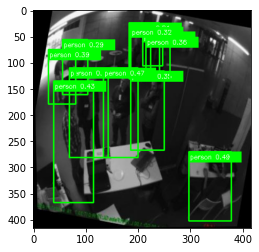

12 person


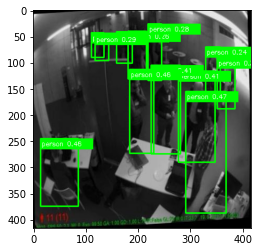

14 person


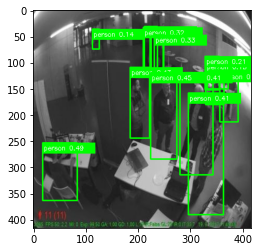

15 person


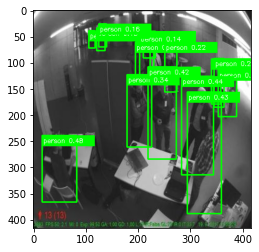

18 person


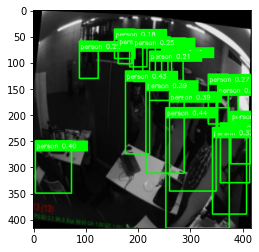

18 person


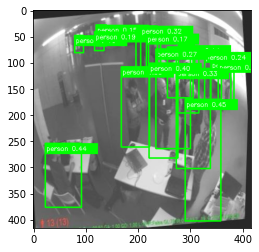

15 person


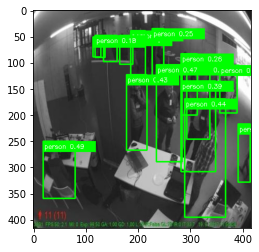

In [7]:
for number, test_img_path in enumerate(test_img_paths[0:18]):
    img_org = cv2.imread(test_img_path)
    img = img_org.copy()
    
    h, w, _ = img_org.shape
    img, ratio, (dw, dh) = letterbox(img, (416,416), auto=False)
    
    img = img[:, :, ::-1]
    img = img.astype(np.uint8)
    driver_in = np.expand_dims(img, 0)

    output = driver.execute(driver_in)
    output = scale*output
    output = output.transpose(0,3,1,2)

    pred = detect_head([output])[0]

    pred = non_max_suppression(pred, conf_thres=conf_thres, iou_thres=iou_thres, classes=None, max_det=1000)

    boxes_detected, class_names_detected, probs_detected = [], [], []
    # Process predictions
    for i, det in enumerate(pred):  # per image
        if len(det):
            # Rescale boxes from img_size to im0 size
            det[:, :4] = scale_coords(img.shape, det[:, :4], img_org.shape).round()
            # Print results
            for c in np.unique(det[:, -1]):
                n = (det[:, -1] == c).sum()  # detections per class
                print(f"{n} {names[int(c)]}")  # add to string
            # Write results
            for *xyxy, conf, cls in reversed(det):
                c = int(cls)  # integer class
                label = f'{names[c]} {conf:.2f}'
                boxes_detected.append(xyxy)
                class_names_detected.append(names[c])
                probs_detected.append(conf)

    # Visualize.
    image_boxes = visualize_boxes(img_org, boxes_detected, class_names_detected, probs_detected)
    cv2.imwrite(output_path+f"{number}.jpg", image_boxes)
    
    plt.imshow(cv2.cvtColor(image_boxes, cv2.COLOR_BGR2RGB))
    plt.show()


## Video Inference

In [13]:
# Configuration constants
VIDEO_PATH = "./data/test.mp4"  
OUTPUT_DIR = "./video_outputs/" 
CONF_THRES = 0.10                
IOU_THRES = 0.5                 
MAX_FRAMES = -1                  

In [14]:
def main():

    # Setup output directory
    output_path = OUTPUT_DIR
    if not os.path.exists(output_path):
        os.makedirs(output_path)

    # Initialize driver
    driver = FINNExampleOverlay(
        bitfile_name="./resizer.bit",
        platform="zynq-iodma",
        io_shape_dict=io_shape_dict,
        batch_size=1,
        runtime_weight_dir="runtime_weights/",
    )

    # Model configuration
    names = ["person"]
    nc = 1
    anchors = np.array([[10, 14, 23, 27, 37, 58]]) / np.array([32])
    scale = np.load("scale.npy")
    detect_head = Detect(nc, anchors)
    conf_thres = CONF_THRES
    iou_thres = IOU_THRES

    # Open video
    print(f"Opening video: {VIDEO_PATH}")
    cap = cv2.VideoCapture(VIDEO_PATH)
    if not cap.isOpened():
        raise RuntimeError(f"❌ Could not open video file: {VIDEO_PATH}")

    frame_in_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_in_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print(f"Video resolution: {frame_in_w}x{frame_in_h} @ {fps:.2f} FPS")
    print(f"Output will be saved to: {output_path}")

    start_time = time.time()
    frame_count = 0

    try:
        while True:
            if MAX_FRAMES > 0 and frame_count >= MAX_FRAMES:
                print(
                    f"\n✓ Reached max_frames limit ({MAX_FRAMES}). "
                    f"Stopping."
                )
                break

            ret, img_org = cap.read()
            if not ret or img_org is None:
                print("\nEnd of video stream")
                break

            elapsed_time = time.time() - start_time
            print(f"\n[Frame {frame_count}] Time: {elapsed_time:.1f}s")

            # Preprocess image (no extra copy)
            img, ratio, (dw, dh) = letterbox(img_org, (416, 416), auto=False)
            img = img[:, :, ::-1].astype(np.uint8)

            # Inference
            driver_in = np.expand_dims(img, 0)
            output = driver.execute(driver_in)
            output = (scale * output).transpose(0, 3, 1, 2)

            # Detection
            pred = detect_head([output])[0]
            pred = non_max_suppression(
                pred,
                conf_thres=conf_thres,
                iou_thres=iou_thres,
                classes=None,
                max_det=1000,
            )

            # Extract detections
            boxes_detected, class_names_detected, probs_detected = [], [], []

            if len(pred[0]) > 0:
                det = pred[0]
                det[:, :4] = scale_coords(
                    img.shape, det[:, :4], img_org.shape
                ).round()

                for *xyxy, conf, cls in det:
                    boxes_detected.append(xyxy)
                    class_names_detected.append(names[int(cls)])
                    probs_detected.append(conf)

                print(f"  ✓ Detected: {len(boxes_detected)} person(s)")
                for i, (box, name, prob) in enumerate(
                    zip(boxes_detected, class_names_detected, probs_detected)
                ):
                    print(f"    {i+1}. {name}: {prob:.2f}")
            else:
                print("  ○ No detections")

            # Visualize and save
            image_boxes = visualize_boxes(
                img_org, boxes_detected, class_names_detected, probs_detected
            )
            output_filename = os.path.join(
                output_path, f"frame_{frame_count:06d}.jpg"
            )
            cv2.imwrite(output_filename, image_boxes)
            print(f"  💾 Saved: {output_filename}")

            frame_count += 1

    finally:
        cap.release()
        cv2.destroyAllWindows()

        total_time = time.time() - start_time
        fps_effective = (
            frame_count / total_time if total_time > 0 else 0.0
        )

        print("\n" + "=" * 50)
        print("✓ Video processing finished")
        print(f"Frames processed: {frame_count}")
        print(f"Total time: {total_time:.2f}s")
        print(f"Effective FPS: {fps_effective:.2f}")
        print(f"Output folder: {output_path}")
        print("=" * 50)

In [ ]:
if __name__ == "__main__":
    main()